# Bayesian Optimization Pipeline for Model A: Active-Material Milling
**LiftOFF Technology / Genesis Mission Framework**

This notebook implements the Bayesian Optimization (BO) pipeline for **Model A (Active-Material Milling)** using Gaussian Process surrogate modeling and single-objective acquisition function optimization (`qNEI`).

### Framework Architecture:
* **Directory Structure:** Located in `Genesis_Project/Model/BO_Model_A.ipynb`
* **Raw Data Location:** `Genesis_Project/Data/raw_data/` (58 particle CSV files)
* **Processed Data Location:** `Genesis_Project/Data/milling_summary_processed.csv`
* **Surrogate Model:** Single-Task Gaussian Process (`SingleTaskGP`) with Matérn $\nu=2.5$ covariance kernel
* **Acquisition Function:** `qNoisyExpectedImprovement` (qNEI) for noisy observation single-objective optimization
* **Input Parameter:** Cumulative Specific Energy Dose $E_{\text{cum}} = C \cdot N^3 \cdot t$ (kJ/g)
* **Target Objective:** Target particle size $D_{50} \approx 200\text{ nm}$

In [20]:
%pip install anyio
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import gpytorch
import botorch
from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.kernels import ScaleKernel, MaternKernel
from botorch.acquisition import qNoisyExpectedImprovement, qExpectedImprovement
try:
    from botorch.acquisition.logei import qLogNoisyExpectedImprovement
except ImportError:
    qLogNoisyExpectedImprovement = qNoisyExpectedImprovement
from botorch.optim import optimize_acqf

try:
    import Data_Preprocessing as dp
except ImportError:
    import Data_Preprocessing as dp

sns.set_theme(style="whitegrid", palette="muted")
print("PyTorch Version:", torch.__version__)
print("BoTorch Version:", botorch.__version__)


Note: you may need to restart the kernel to use updated packages.
PyTorch Version: 2.14.0
BoTorch Version: 0.18.1


Raw Data Folder: /Users/kevinbabashov/Documents/Fall 2026/Deshwal_Lab_Work/Gensis_Research_Project/Genesis_Project/Data/raw_data
Output CSV Path: /Users/kevinbabashov/Documents/Fall 2026/Deshwal_Lab_Work/Gensis_Research_Project/Genesis_Project/Data/milling_summary_processed.csv
Loading raw milling CSVs...
Loaded 11954 total particle records.
Cleaning particle measurements...
Retained 9993 valid non-border particles.
Aggregating batch-level metrics...
Successfully exported summary data to '/Users/kevinbabashov/Documents/Fall 2026/Deshwal_Lab_Work/Gensis_Research_Project/Genesis_Project/Data/milling_summary_processed.csv'.


,Condition,RPM,Milling_Time_h,E_cum_kJ_g,Valid_Particle_Count,D10_nm,D50_nm,D90_nm,Span
0,260714_900_1_30000,900.0,1.0,1.29,179,102.67,157.15,271.23,1.073
1,261006_900_1_5000,900.0,1.0,1.29,883,577.70,1126.42,2020.70,1.281
2,261013_900_1_10000,900.0,1.0,1.29,676,265.37,563.63,1093.27,1.469
3,260714_900_2_30000,900.0,2.0,2.58,258,98.31,153.98,243.59,0.943
4,260720_900_2_30000,900.0,2.0,2.58,171,109.94,171.65,276.71,0.972
5,261006_900_2_20000,900.0,2.0,2.58,849,151.46,263.36,491.51,1.291
6,261013_900_2_20000,900.0,2.0,2.58,850,137.03,264.92,517.29,1.435
7,261006_900_3_20000,900.0,3.0,3.87,1036,153.36,252.31,450.50,1.178
8,261013_900_3_20000,900.0,3.0,3.87,780,155.27,265.07,482.21,1.233
9,261006_900_4_30000,900.0,4.0,5.16,734,118.20,195.53,339.60,1.132


/var/folders/zr/vfkt6hqx4vl7hmnlbxptt2x80000gn/T/ipykernel_87303/3714683201.py:24: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/zr/vfkt6hqx4vl7hmnlbxptt2x80000gn/T/ipykernel_87303/3714683201.py:25: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(os.path.join(SCRIPT_DIR, 'milling_energy_vs_particle_size.png'), dpi=300)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


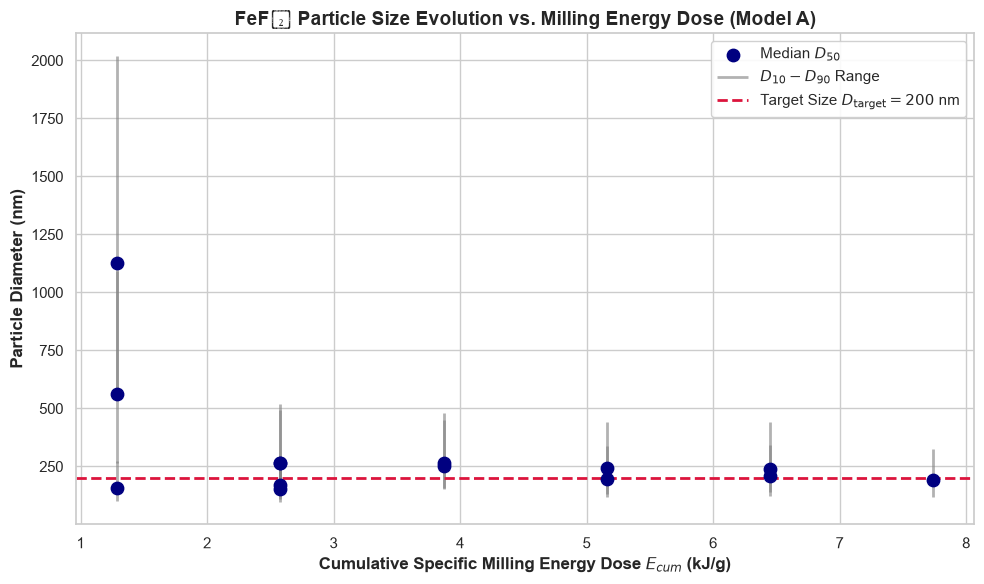

In [21]:
SCRIPT_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
RAW_DATA_DIR = os.path.abspath(os.path.join(SCRIPT_DIR, "..", "Data", "raw_data"))
PROCESSED_CSV = os.path.abspath(os.path.join(SCRIPT_DIR, "..", "Data", "milling_summary_processed.csv"))

print(f"Raw Data Folder: {RAW_DATA_DIR}")
print(f"Output CSV Path: {PROCESSED_CSV}")

# Process raw CSV datasets using module
summary_df = dp.process_pipeline(data_dir=RAW_DATA_DIR, output_csv=PROCESSED_CSV)

# Display summary table
display(summary_df[['Condition', 'RPM', 'Milling_Time_h', 'E_cum_kJ_g', 'Valid_Particle_Count', 'D10_nm', 'D50_nm', 'D90_nm', 'Span']])

# Visualization of particle size reduction vs E_cum
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(summary_df['E_cum_kJ_g'], summary_df['D50_nm'], color='navy', s=80, label=r'Median $D_{50}$', zorder=5)
ax.vlines(summary_df['E_cum_kJ_g'], summary_df['D10_nm'], summary_df['D90_nm'], color='gray', alpha=0.6, linewidth=2, label=r'$D_{10} - D_{90}$ Range')
ax.axhline(200, color='crimson', linestyle='--', linewidth=2, label=r'Target Size $D_{\text{target}} = 200$ nm')

ax.set_xlabel('Cumulative Specific Milling Energy Dose $E_{cum}$ (kJ/g)', fontsize=12, fontweight='bold')
ax.set_ylabel('Particle Diameter (nm)', fontsize=12, fontweight='bold')
ax.set_title('FeF₂ Particle Size Evolution vs. Milling Energy Dose (Model A)', fontsize=14, fontweight='bold')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(SCRIPT_DIR, 'milling_energy_vs_particle_size.png'), dpi=300)
plt.show()

In [22]:
# build & fit Gaussian Process Surrogate Model (SingleTaskGP)
X_raw = summary_df['E_cum_kJ_g'].values.reshape(-1, 1)

# log10-transform target particle diameter D50 (nm) to stabilize multi-scale variance
Y_raw = np.log10(summary_df['D50_nm'].values.reshape(-1, 1))

X_min, X_max = X_raw.min(), X_raw.max()
Y_min, Y_max = Y_raw.min(), Y_raw.max()

# standardize features to [0, 1] for BO numerical stability
train_x = torch.tensor((X_raw - X_min) / (X_max - X_min + 1e-6), dtype=torch.float64)
train_y = torch.tensor((Y_raw - Y_min) / (Y_max - Y_min + 1e-6), dtype=torch.float64)

# initialize GP with Matern 2.5 Covariance Kernel
covar_module = ScaleKernel(MaternKernel(nu=2.5))
gp = SingleTaskGP(train_x, train_y, covar_module=covar_module)
mll = ExactMarginalLogLikelihood(gp.likelihood, gp)

# train GP hyper-parameters
fit_gpytorch_mll(mll)
print("Gaussian Process Model Trained Successfully!")


Gaussian Process Model Trained Successfully!


Leave-One-Out Cross-Validation (LOOCV) R² Score: -0.689


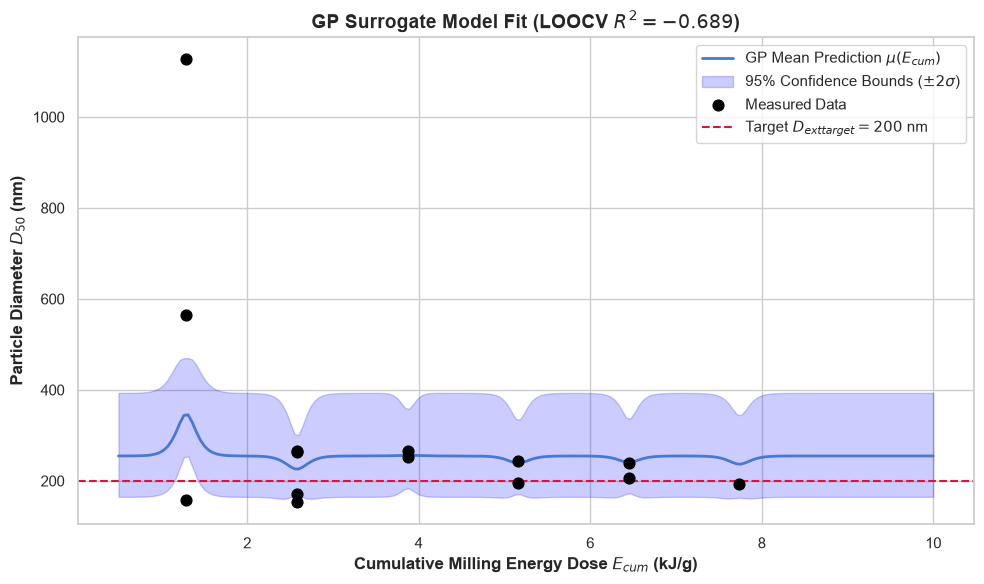

In [23]:
# model LOOCV Evaluation & 95% Confidence Band
loocv_preds_log = []
for i in range(len(train_x)):
    mask = torch.ones(len(train_x), dtype=torch.bool)
    mask[i] = False
    sub_x, sub_y = train_x[mask], train_y[mask]
    sub_gp = SingleTaskGP(sub_x, sub_y, covar_module=ScaleKernel(MaternKernel(nu=2.5)))
    sub_mll = ExactMarginalLogLikelihood(sub_gp.likelihood, sub_gp)
    fit_gpytorch_mll(sub_mll)
    with torch.no_grad():
        posterior = sub_gp.posterior(train_x[i:i+1])
        loocv_preds_log.append(posterior.mean.item())

# de-normalize back to log10 space
loocv_preds_log = np.array(loocv_preds_log) * (Y_max - Y_min + 1e-6) + Y_min

# evaluate R2 score on log10 scale
r2 = 1 - (np.sum((Y_raw.flatten() - loocv_preds_log)**2) / np.sum((Y_raw.flatten() - np.mean(Y_raw.flatten()))**2))
print(f"Leave-One-Out Cross-Validation (LOOCV) R² Score: {r2:.3f}")

# continuous prediction plot over E_cum domain
test_x_raw = np.linspace(0.5, 10.0, 200).reshape(-1, 1)
test_x_norm = torch.tensor((test_x_raw - X_min) / (X_max - X_min + 1e-6), dtype=torch.float64)

gp.eval()
with torch.no_grad():
    posterior = gp.posterior(test_x_norm)
    mean_log = posterior.mean.numpy().flatten() * (Y_max - Y_min + 1e-6) + Y_min
    std_log = np.sqrt(posterior.variance.numpy().flatten()) * (Y_max - Y_min + 1e-6)

# exponentiate log10 predictions back to nanometers for visualization
mean_d50 = 10 ** mean_log
lower_d50 = 10 ** (mean_log - 2 * std_log)
upper_d50 = 10 ** (mean_log + 2 * std_log)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(test_x_raw, mean_d50, 'b-', label=r'GP Mean Prediction $\mu(E_{cum})$', linewidth=2)
ax.fill_between(test_x_raw.flatten(), lower_d50, upper_d50, color='blue', alpha=0.2, label=r'95% Confidence Bounds ($\pm 2\sigma$)')
ax.scatter(X_raw, summary_df['D50_nm'], color='black', s=60, label='Measured Data', zorder=5)
ax.axhline(200, color='crimson', linestyle='--', label=r'Target $D_{	ext{target}} = 200$ nm')
ax.set_xlabel('Cumulative Milling Energy Dose $E_{cum}$ (kJ/g)', fontsize=12, fontweight='bold')
ax.set_ylabel('Particle Diameter $D_{50}$ (nm)', fontsize=12, fontweight='bold')
ax.set_title(f'GP Surrogate Model Fit (LOOCV $R^2 = {r2:.3f}$)', fontsize=14, fontweight='bold')
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig(os.path.join(SCRIPT_DIR, 'gp_model_fit.png'), dpi=300)
plt.show()


In [24]:
# Step 5: Acquisition Function Optimization & Recipe Recommendation
# Objective: Minimize deviation from D_target = 200 nm in log10 space
target_d50_log = np.log10(200.0)
target_d50_norm = (target_d50_log - Y_min) / (Y_max - Y_min + 1e-6)

acq_func = qLogNoisyExpectedImprovement(
    model=gp,
    X_baseline=train_x,
    prune_baseline=True
)

bounds = torch.tensor([[0.0], [1.0]], dtype=torch.float64)
candidate_norm, acq_value = optimize_acqf(
    acq_function=acq_func,
    bounds=bounds,
    q=1,
    num_restarts=10,
    raw_samples=512
)

rec_E_cum = candidate_norm.item() * (X_max - X_min + 1e-6) + X_min
rpm_fixed = 900.0
energy_per_hour = 1.29
recommended_time_h = rec_E_cum / energy_per_hour

print("     BAYESIAN OPTIMIZATION RECOMMENDATION \n")
print(f"Optimal Cumulative Energy Dose E_cum*: {rec_E_cum:.2f} kJ/g")
print(f"Target Mill Speed:                      {rpm_fixed:.0f} RPM")
print(f"Recommended Milling Duration:          {recommended_time_h:.2f} Hours ({recommended_time_h*60:.0f} Minutes)")


     BAYESIAN OPTIMIZATION RECOMMENDATION 

Optimal Cumulative Energy Dose E_cum*: 1.38 kJ/g
Target Mill Speed:                      900 RPM
Recommended Milling Duration:          1.07 Hours (64 Minutes)


/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
